In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd

In [3]:
#Importing one of the results:
filepath = '/lustre/storeB/project/fou/hi/foccus/experiments/rollout-benchmark/lr3.5e6-rs3-i0-m3/logs/mlflow/124883160109034645/a43f19277389461a813e4bca6b2b430e/metrics'
""" 
For an overfitting analysis - we focus on the validation and training loss, with epochs on the x-axis. We will be importing the relevant metrics only for simplicity
I believe the metrics are given as: ['ID', 'Vals', 'Steps']
"""
n = ['ID', 'Vals', 'Steps']
epochs_0 = pd.read_csv(f'{filepath}/epoch', header = None, sep = r"\s+", names = n)
val_loss_epoch_0 = pd.read_csv(f'{filepath}/val_multi_dataset_loss_step', header = None, sep = r"\s+", names = n)
train_loss_epoch_0 = pd.read_csv(f'{filepath}/train_multi_dataset_loss_step', header = None , sep = r"\s+", names = n)

In [4]:
epochs_0

,ID,Vals,Steps
0,1793223476346,0.0,99
1,1793224624398,0.0,199
2,1793225773011,0.0,299
3,1793226921834,0.0,399
4,1793228071453,0.0,499
...,...,...,...
343,1793616128735,9.0,33499
344,1793617281626,9.0,33599
345,1793618434858,9.0,33699
346,1793619587211,9.0,33799


In [5]:
val_loss_epoch_0

,ID,Vals,Steps
0,1793263721423,0.005950,0
1,1793263722659,0.005995,1
2,1793263723866,0.006654,2
3,1793263725073,0.006499,3
4,1793263726278,0.006816,4
...,...,...,...
6475,1793603029755,0.006120,6475
6476,1793603030959,0.005985,6476
6477,1793603032155,0.005919,6477
6478,1793603033355,0.006101,6478


In [14]:
train_loss_epoch_0

,ID,Vals,Steps,Normalized_Vals
0,1793223476346,0.008381,99,0.634240
1,1793224624398,0.007437,199,0.329159
2,1793225773011,0.008171,299,0.566247
3,1793226921834,0.008098,399,0.542820
4,1793228071453,0.009353,499,0.948557
...,...,...,...,...
334,1793616128735,0.007679,33499,0.407249
335,1793617281626,0.007646,33599,0.396764
336,1793618434858,0.007217,33699,0.257976
337,1793619587211,0.007421,33799,0.323783


In [6]:
resampled_val = val_loss_epoch_0.iloc[99::100].reset_index(drop = True)

In [7]:
resampled_val

,ID,Vals,Steps
0,1793263840415,0.005313,99
1,1793263960592,0.005449,199
2,1793264080726,0.005472,299
3,1793264200837,0.005347,399
4,1793264320937,0.006292,499
...,...,...,...
59,1793602456183,0.005268,5999
60,1793602576729,0.005573,6099
61,1793602697249,0.005575,6199
62,1793602817741,0.007052,6299


In [8]:
interpolated_val = val_loss_epoch_0.set_index('Steps').reindex(train_loss_epoch_0['Steps']).interpolate(method = 'linear').reset_index()

In [9]:
interpolated_val['Steps']
"""
interpolated_reset_index = interpolated_val.reset_index()
interpolated_reset_index['Steps']
"""

"\ninterpolated_reset_index = interpolated_val.reset_index()\ninterpolated_reset_index['Steps']\n"

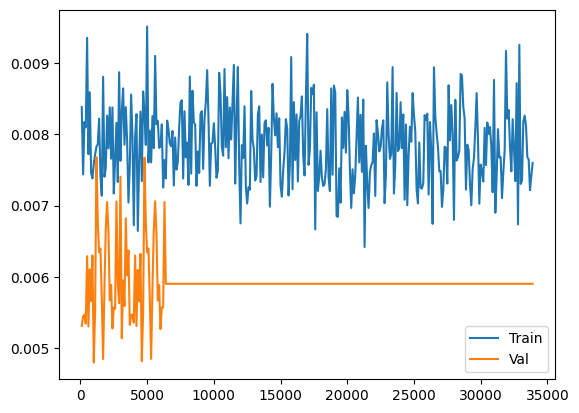

In [19]:
plt.plot(train_loss_epoch_0['Steps'], train_loss_epoch_0['Vals'], label = 'Train')
plt.plot(interpolated_val['Steps'], interpolated_val['Vals'], label = 'Val')
#plt.plot(val_loss_epoch_0['Steps'], val_loss_epoch_0['Vals'], label = 'Val')
plt.legend()
#plt.xlim(0,10000)

In [11]:
""" 
Kjøre tre timer for alle checkpoints - sjekke om RMSE øker med checkpoint for å vurdere overfitting

eller 

Merge de ulike ID-ene for benchmark uten rollout
"""

' \nKjøre tre timer for alle checkpoints - sjekke om RMSE øker med checkpoint for å vurdere overfitting\n\neller \n\nMerge de ulike ID-ene for benchmark uten rollout\n'

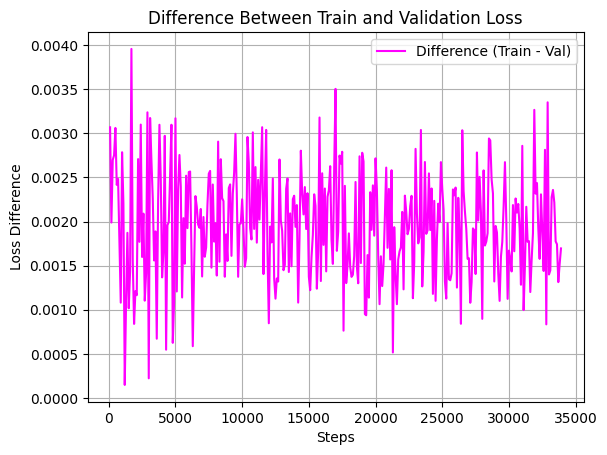

In [12]:
difference = train_loss_epoch_0['Vals'].values - interpolated_val['Vals'].values

plt.plot(train_loss_epoch_0['Steps'], difference, label='Difference (Train - Val)', color='magenta')
plt.xlabel('Steps')
plt.ylabel('Loss Difference')
plt.title('Difference Between Train and Validation Loss')
plt.legend()
plt.grid()
plt.show()